# PART 3: Inferential Hypothesis Testing & Predictive Time-Series Forecasting

**Objective:** Perform inferential statistical tests to verify business hypotheses and construct a time-series forecasting model with confidence intervals.

## Module A - Statistical Inferential Hypothesis Testing
In this module, we will test two primary hypotheses:
1. **Hypothesis 1:** Are there statistically significant differences in the average revenue (Monetary value) among the customer segments we created?
2. **Hypothesis 2:** Is a customer's segment (behavior) independent of whether they are located in the UK or Internationally?

In [1]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
import itertools
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

# Load the Dimension table generated from Part 2
dim_customers = pd.read_csv('../data/processed/dim_customers_rfm.csv')
display(dim_customers.head())

,CustomerID,Recency,Frequency,Monetary,Cluster_Label,Segment_Name,Country
0,12346,326,1,124.80,2,Lost/At Risk,United Kingdom
1,12347,2,7,4185.20,0,Champions/VIP,Iceland
2,12348,75,4,1530.03,1,Loyal/Regular Customers,Finland
3,12349,19,1,1443.50,1,Loyal/Regular Customers,Italy
4,12350,310,1,309.35,2,Lost/At Risk,Norway


### Hypothesis 1: Revenue Differences Among Segments
* **$H_0$:** There is NO difference in average spending (Monetary) among the customer segments.
* **$H_1$:** At least one segment has a significantly different average spending.

First, we will check the assumptions of ANOVA: Normality (Shapiro-Wilk) and Homogeneity of Variances (Levene's Test).

In [2]:
groups = [dim_customers[dim_customers['Segment_Name'] == seg]['Monetary'] for seg in dim_customers['Segment_Name'].unique()]
segment_names = dim_customers['Segment_Name'].unique()

print("--- 1. Shapiro-Wilk Test for Normality ---")
# Note: Financial data is notoriously right-skewed. We expect normality to fail.
for seg, data in zip(segment_names, groups):
    stat, p = stats.shapiro(data)
    print(f"Segment: {seg:25} | p-value: {p:.4e} | Normal: {p > 0.05}")

print("\n--- 2. Levene's Test for Equal Variances ---")
stat, p = stats.levene(*groups)
print(f"Statistic: {stat:.4f} | p-value: {p:.4e} | Equal Variances: {p > 0.05}")

--- 1. Shapiro-Wilk Test for Normality ---
Segment: Lost/At Risk              | p-value: 1.0621e-42 | Normal: False
Segment: Champions/VIP             | p-value: 1.1144e-46 | Normal: False
Segment: Loyal/Regular Customers   | p-value: 7.0780e-42 | Normal: False

--- 2. Levene's Test for Equal Variances ---
Statistic: 146.4875 | p-value: 2.7471e-62 | Equal Variances: False


### Why choose Kruskal-Wallis over One-Way ANOVA?

Based on the statistical tests run above, our data clearly violates the two primary assumptions required for One-Way ANOVA:

1. **Normality (Shapiro-Wilk Test):** 
   - The p-values for all three segments (Lost/At Risk: `1.06e-42`, Champions/VIP: `1.11e-46`, Loyal/Regular: `7.08e-42`) are significantly less than `0.05`. 
   - **Conclusion:** The data does NOT follow a normal distribution (it is highly skewed due to extreme outliers).

2. **Homogeneity of Variances (Levene's Test):** 
   - The p-value (`2.75e-62`) is also far below `0.05`. 
   - **Conclusion:** The variance (spread) of spending is NOT equal across the different segments.

Because our data heavily violates both assumptions, using ANOVA would lead to mathematically invalid conclusions. 
**Kruskal-Wallis** is a non-parametric alternative. Instead of comparing raw dollar amounts, it ranks all customers from lowest to highest spend and compares the median ranks. This makes it completely immune to extreme outliers and skewed data, making it the most robust choice for our analysis.

*If the Kruskal-Wallis test is significant, we will follow up with **Pairwise Mann-Whitney U tests** (with Bonferroni correction) as the post-hoc test to identify exactly which segments differ.*

--- 3. Kruskal-Wallis H-test ---
K-W Statistic: 2845.6365 | p-value: 0.0000e+00

CONCLUSION: REJECT H0. There is a statistically significant difference in spending among the customer segments.

--- Pairwise Mann-Whitney U (Post-hoc) ---
Bonferroni adjusted Alpha level: 0.0167

Lost/At Risk vs Champions/VIP:
   p-value: 0.0000e+00 | Significant Difference: True
Lost/At Risk vs Loyal/Regular Customers:
   p-value: 0.0000e+00 | Significant Difference: True
Champions/VIP vs Loyal/Regular Customers:
   p-value: 3.8504e-262 | Significant Difference: True


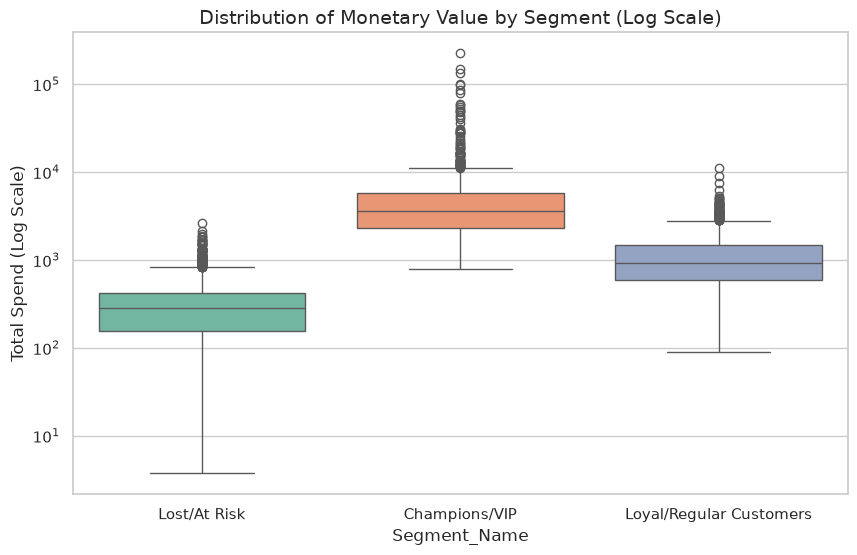

In [3]:
print("--- 3. Kruskal-Wallis H-test ---")
stat, p = stats.kruskal(*groups)
print(f"K-W Statistic: {stat:.4f} | p-value: {p:.4e}")

if p < 0.05:
    print("\nCONCLUSION: REJECT H0. There is a statistically significant difference in spending among the customer segments.")
    
    # Post-hoc pairwise Mann-Whitney U tests with Bonferroni correction
    print("\n--- Pairwise Mann-Whitney U (Post-hoc) ---")
    num_tests = len(segment_names) * (len(segment_names) - 1) / 2
    alpha_bonf = 0.05 / num_tests
    print(f"Bonferroni adjusted Alpha level: {alpha_bonf:.4f}\n")
    
    for s1, s2 in itertools.combinations(segment_names, 2):
        data1 = dim_customers[dim_customers['Segment_Name'] == s1]['Monetary']
        data2 = dim_customers[dim_customers['Segment_Name'] == s2]['Monetary']
        stat_mw, p_mw = stats.mannwhitneyu(data1, data2, alternative='two-sided')
        print(f"{s1} vs {s2}:")
        print(f"   p-value: {p_mw:.4e} | Significant Difference: {p_mw < alpha_bonf}")
else:
    print("\nCONCLUSION: FAIL TO REJECT H0. No significant difference found.")
    
# Visualization
plt.figure(figsize=(10, 6))
sns.boxplot(x='Segment_Name', y='Monetary', data=dim_customers, palette='Set2')
plt.yscale('log') # Log scale for better visibility of outliers
plt.title('Distribution of Monetary Value by Segment (Log Scale)', fontsize=14)
plt.ylabel('Total Spend (Log Scale)')
plt.show()

### Hypothesis 2: Independence between Geography and Segments
* **$H_0$:** A customer's segment is independent of their geographical location.
* **$H_1$:** A customer's segment is dependent on their geographical location.

Since the vast majority of our customers are from the UK, we will group `Country` into "UK" and "Non-UK" to ensure our Chi-Square Expected Frequencies are $>5$.

--- Contingency Table (Observed Frequencies) ---


Segment_Name,Champions/VIP,Lost/At Risk,Loyal/Regular Customers
Region,,,
Non-UK,84,159,175
UK,675,1714,1531



--- Chi-Square Test Results ---
Chi-Square Statistic : 5.3730
p-value              : 6.8120e-02
Degrees of Freedom   : 2

CONCLUSION: FAIL TO REJECT H0. Customer Segment is strictly independent of Region.

Cramer's V Effect Size: 0.0352 (0 = No association, 1 = Perfect association)


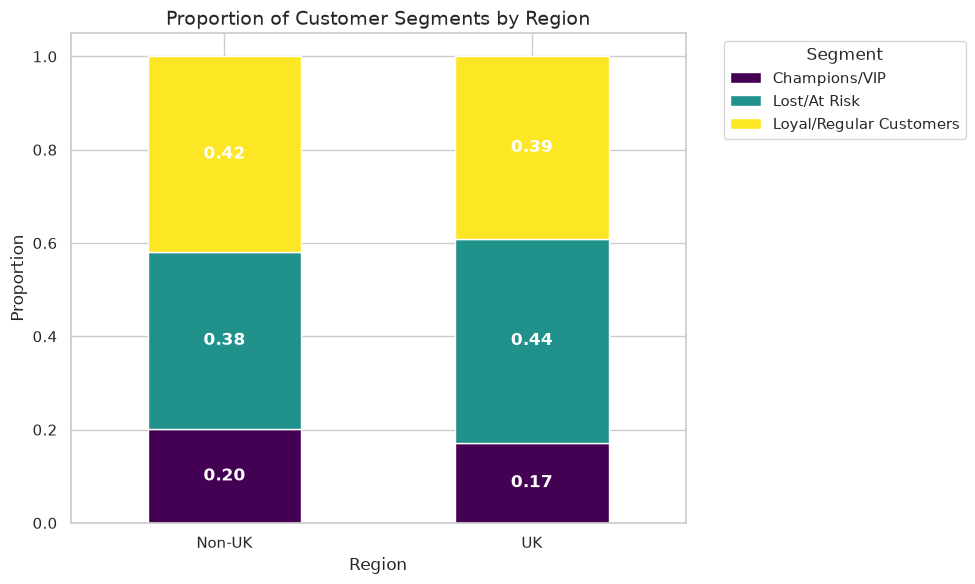

In [4]:
# Create Region column
dim_customers['Region'] = np.where(dim_customers['Country'] == 'United Kingdom', 'UK', 'Non-UK')

# Contingency Table
contingency_table = pd.crosstab(dim_customers['Region'], dim_customers['Segment_Name'])
print("--- Contingency Table (Observed Frequencies) ---")
display(contingency_table)

# Chi-Square Test
chi2, p, dof, expected = stats.chi2_contingency(contingency_table)

print("\n--- Chi-Square Test Results ---")
print(f"Chi-Square Statistic : {chi2:.4f}")
print(f"p-value              : {p:.4e}")
print(f"Degrees of Freedom   : {dof}")

if p < 0.05:
    print("\nCONCLUSION: REJECT H0. There is a statistically significant relationship between Customer Segment and Region.")
else:
    print("\nCONCLUSION: FAIL TO REJECT H0. Customer Segment is strictly independent of Region.")
    
# Calculate Cramer's V for effect size
n = contingency_table.sum().sum()
min_dim = min(contingency_table.shape) - 1
cramer_v = np.sqrt(chi2 / (n * min_dim))
print(f"\nCramer's V Effect Size: {cramer_v:.4f} (0 = No association, 1 = Perfect association)")

# Visualizing proportions
contingency_pct = contingency_table.div(contingency_table.sum(axis=1), axis=0)
ax = contingency_pct.plot(kind='bar', stacked=True, figsize=(10, 6), colormap='viridis')
plt.title('Proportion of Customer Segments by Region', fontsize=14)
plt.ylabel('Proportion')
plt.legend(title='Segment', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=0)

# Add percentage labels
for c in ax.containers:
    ax.bar_label(c, label_type='center', fmt='%.2f', color='white', fontweight='bold')

plt.tight_layout()
plt.show()

## Module B - Time-Series Aggregation & Stationarity Diagnostics
In this module, we prepare the data for predictive modeling. We will aggregate historical transactions into a Time Series, decompose it to understand underlying patterns, and test it for stationarity.

### Why aggregate by Week ('W') instead of Day ('D')?
When dealing with retail data, Daily revenue is often highly volatile due to day-of-week seasonality (e.g., massive spikes on weekends, drops on Mondays). While a forecasting model can learn this 7-day seasonality, predicting daily fluctuations for a medium-to-long term horizon (8-12 weeks) causes errors to compound rapidly.

By aggregating data to the **Weekly** level, we "smooth out" the micro-level day-of-week seasonality. This allows the forecasting model to focus on the macro-level **Trend** and broader seasonal cycles (e.g., end-of-month or holiday spikes). Weekly aggregation provides a much more stable and accurate projection for strategic business planning over a 3-month horizon.

Total Weeks: 54


InvoiceDate
2010-12-05    137118.49
2010-12-12    178896.89
2010-12-19    147379.00
2010-12-26     41897.18
2011-01-02         0.00
Freq: W-SUN, Name: TotalSpend, dtype: float64

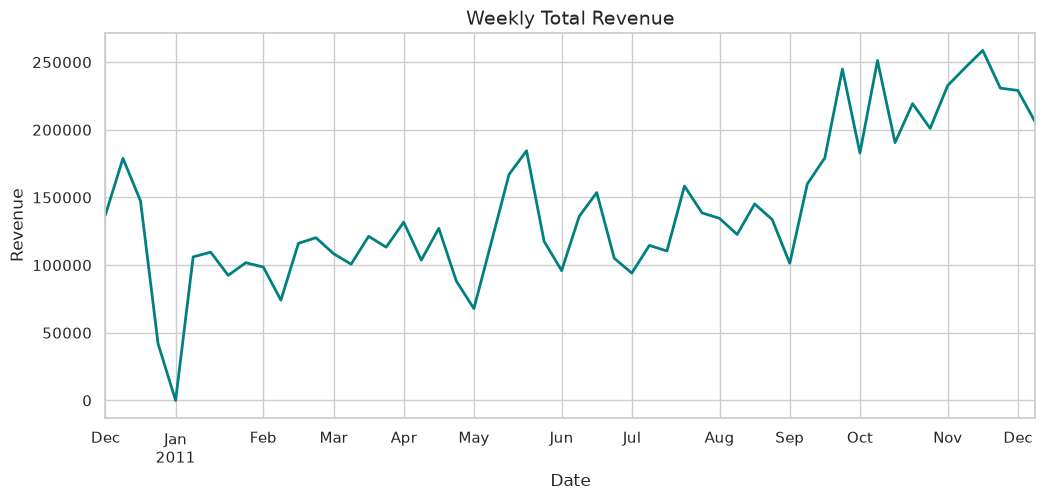

In [6]:
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller, kpss

# Load Fact table (Transactions)
fact_transactions = pd.read_csv('../data/processed/fact_transactions.csv')
fact_transactions['InvoiceDate'] = pd.to_datetime(fact_transactions['InvoiceDate'])

# Aggregate to Weekly ('W') Total Revenue
# Using 'W' (Weekly) instead of 'D' (Daily) smooths out weekend noise and creates a stabler trend for forecasting.
weekly_sales = fact_transactions.set_index('InvoiceDate').resample('W')['TotalSpend'].sum()

print(f"Total Weeks: {len(weekly_sales)}")
display(weekly_sales.head())

# Plot the raw weekly series
plt.figure(figsize=(12, 5))
weekly_sales.plot(color='teal', linewidth=2)
plt.title('Weekly Total Revenue', fontsize=14)
plt.ylabel('Revenue')
plt.xlabel('Date')
plt.show()

### Time Series Decomposition
We decompose the time series into 3 fundamental components:
1. **Trend:** The underlying long-term direction of sales.
2. **Seasonal:** Repeating short-term cycles.
3. **Residual:** Random noise/fluctuations.
We use an *Additive* model here.

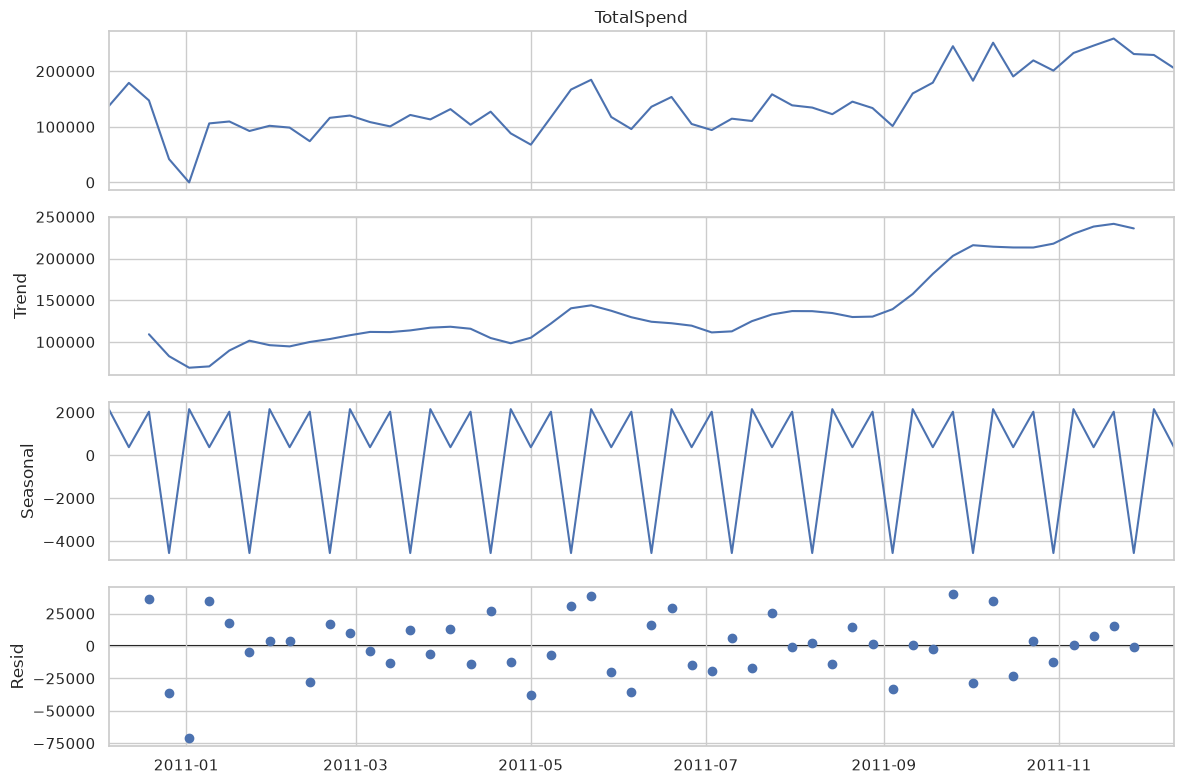

In [7]:
# Decompose the Time Series
# Period = 4 (assuming roughly a 4-week/monthly cycle in weekly data)
decomposition = seasonal_decompose(weekly_sales, model='additive', period=4)

fig = decomposition.plot()
fig.set_size_inches(12, 8)
plt.tight_layout()
plt.show()

### Stationarity Diagnostics (ADF & KPSS)
A time series must be "Stationary" (constant mean and variance over time) for ARIMA models to work properly.
* **ADF Test:** $H_0$ = Non-Stationary. (We want p < 0.05 to reject $H_0$).
* **KPSS Test:** $H_0$ = Stationary. (We want p > 0.05 to fail to reject $H_0$).

In [8]:
def test_stationarity(timeseries):
    print("--- Augmented Dickey-Fuller (ADF) Test ---")
    adf_result = adfuller(timeseries, autolag='AIC')
    print(f"ADF Statistic: {adf_result[0]:.4f}")
    print(f"p-value: {adf_result[1]:.4e}")
    print(f"Stationary (p < 0.05): {adf_result[1] < 0.05}")
    
    print("\n--- Kwiatkowski-Phillips-Schmidt-Shin (KPSS) Test ---")
    import warnings
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        kpss_result = kpss(timeseries, regression='c', nlags="auto")
    print(f"KPSS Statistic: {kpss_result[0]:.4f}")
    print(f"p-value: {kpss_result[1]:.4f}")
    print(f"Stationary (p > 0.05): {kpss_result[1] > 0.05}")

test_stationarity(weekly_sales)

--- Augmented Dickey-Fuller (ADF) Test ---
ADF Statistic: -0.5378
p-value: 8.8442e-01
Stationary (p < 0.05): False

--- Kwiatkowski-Phillips-Schmidt-Shin (KPSS) Test ---
KPSS Statistic: 0.8592
p-value: 0.0100
Stationary (p > 0.05): False


If the series is non-stationary, we need to apply **Differencing** (calculating the difference between consecutive weeks) to make it stationary before feeding it into the SARIMA model. The `d` parameter in SARIMA handles this.

Testing Stationarity on 1st Order Differenced Series:
--- Augmented Dickey-Fuller (ADF) Test ---
ADF Statistic: -8.2207
p-value: 6.4420e-13
Stationary (p < 0.05): True

--- Kwiatkowski-Phillips-Schmidt-Shin (KPSS) Test ---
KPSS Statistic: 0.1605
p-value: 0.1000
Stationary (p > 0.05): True


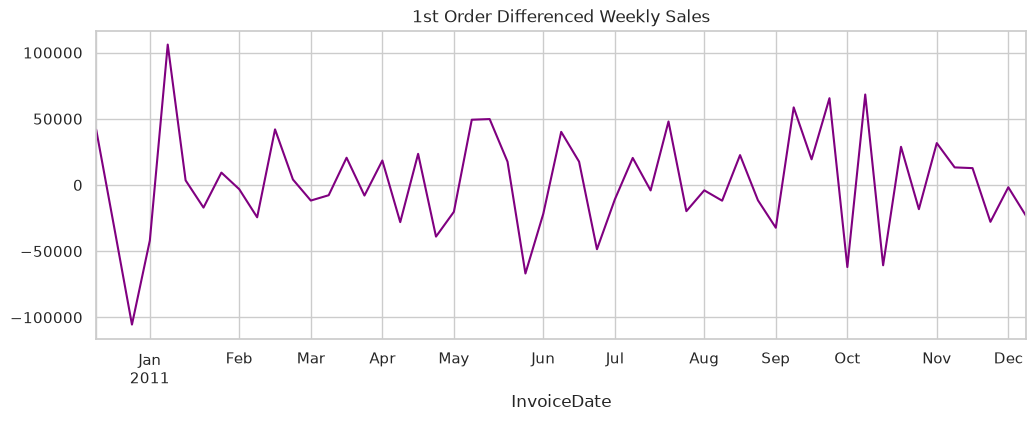

In [9]:
# Testing 1st Order Differencing
print("Testing Stationarity on 1st Order Differenced Series:")
weekly_sales_diff = weekly_sales.diff().dropna()
test_stationarity(weekly_sales_diff)

plt.figure(figsize=(12, 4))
weekly_sales_diff.plot(color='purple')
plt.title('1st Order Differenced Weekly Sales')
plt.show()

---
## Module C - Predictive Modeling (SARIMA)
We will build a **Seasonal AutoRegressive Integrated Moving Average (SARIMA)** model.
First, we strictly split our data chronologically (no random shuffling) to prevent future data leakage. We use 80% of the data for training and 20% for testing.

Train Size: 43 weeks
Test Size: 11 weeks


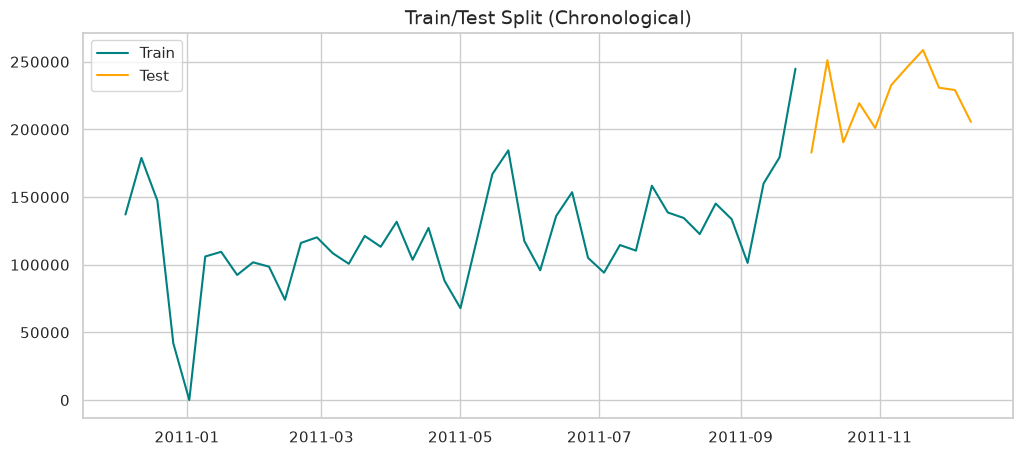

In [13]:
# Train / Test Split (80/20 Chronological)
train_size = int(len(weekly_sales) * 0.8)
train, test = weekly_sales.iloc[:train_size], weekly_sales.iloc[train_size:]

print(f"Train Size: {len(train)} weeks")
print(f"Test Size: {len(test)} weeks")

plt.figure(figsize=(12, 5))
plt.plot(train.index, train.values, label='Train', color='teal')
plt.plot(test.index, test.values, label='Test', color='orange')
plt.title('Train/Test Split (Chronological)', fontsize=14)
plt.legend()
plt.show()

### Hyperparameter Selection (Auto ARIMA)
We use `pmdarima` to automatically run a grid search and find the optimal $(p, d, q) \times (P, D, Q)_s$ hyperparameters by minimizing the AIC score. We already know from our stationarity test that $d=1$ is a good starting point.

In [14]:
import pmdarima as pm

# Note: this can take a minute to run as it searches through many combinations
print("Running Auto-ARIMA Grid Search...")
auto_model = pm.auto_arima(
    train, 
    start_p=0, start_q=0,
    max_p=3, max_q=3,
    m=4,              # Seasonality period (e.g., 4 weeks in a month)
    start_P=0, start_Q=0,
    max_P=2, max_Q=2,
    seasonal=True,
    d=1, D=1,         # We enforce 1st order differencing based on ADF test
    trace=True,
    error_action='ignore',  
    suppress_warnings=True, 
    stepwise=True
)

print("\nOptimal SARIMA Model Found:")
print(auto_model.summary())

Running Auto-ARIMA Grid Search...
Performing stepwise search to minimize aic
 ARIMA(0,1,0)(0,1,0)[4]             : AIC=924.850, Time=0.08 sec
 ARIMA(1,1,0)(1,1,0)[4]             : AIC=923.767, Time=0.05 sec
 ARIMA(0,1,1)(0,1,1)[4]             : AIC=914.544, Time=0.09 sec
 ARIMA(0,1,1)(0,1,0)[4]             : AIC=925.858, Time=0.04 sec
 ARIMA(0,1,1)(1,1,1)[4]             : AIC=915.605, Time=0.11 sec
 ARIMA(0,1,1)(0,1,2)[4]             : AIC=915.745, Time=0.10 sec
 ARIMA(0,1,1)(1,1,0)[4]             : AIC=918.930, Time=0.06 sec
 ARIMA(0,1,1)(1,1,2)[4]             : AIC=917.495, Time=0.24 sec
 ARIMA(0,1,0)(0,1,1)[4]             : AIC=918.023, Time=0.04 sec
 ARIMA(1,1,1)(0,1,1)[4]             : AIC=912.754, Time=0.15 sec
 ARIMA(1,1,1)(0,1,0)[4]             : AIC=916.042, Time=0.08 sec
 ARIMA(1,1,1)(1,1,1)[4]             : AIC=913.805, Time=0.27 sec
 ARIMA(1,1,1)(0,1,2)[4]             : AIC=914.039, Time=0.29 sec
 ARIMA(1,1,1)(1,1,0)[4]             : AIC=914.624, Time=0.12 sec
 ARIMA(1,1,1)

### Understanding the SARIMA Results & Diagnostics
The Auto-ARIMA algorithm has identified the best model based on the lowest AIC score. More importantly, we can check the health of the model by looking at the residual diagnostics at the bottom of the summary:

- **Ljung-Box (Q) Test (Prob(Q) > 0.05):** Tests if there is any pattern left in the errors. A value > 0.05 means our model successfully captured all the information (Trend/Seasonality), leaving only random noise (White Noise).
- **Heteroskedasticity (H) (Prob(H) > 0.05):** Tests if the variance of the errors is constant over time. A value > 0.05 means the model's accuracy is stable and doesn't fluctuate wildly.
- **Jarque-Bera (JB) (Prob(JB) > 0.05):** Tests if the errors are normally distributed. A value > 0.05 indicates the errors follow a healthy bell-curve shape.

*If these p-values are above 0.05, the model is mathematically sound and reliable for forecasting.*

---
## Module D - Model Evaluation & Confidence Boundary Projection
We use the optimal model to predict the Test period and calculate error metrics: MAE, RMSE, MAPE.

--- Model Performance on Test Set ---


,Metric,Value
0,MAE,23024.55
1,RMSE,29830.36
2,MAPE (%),9.85


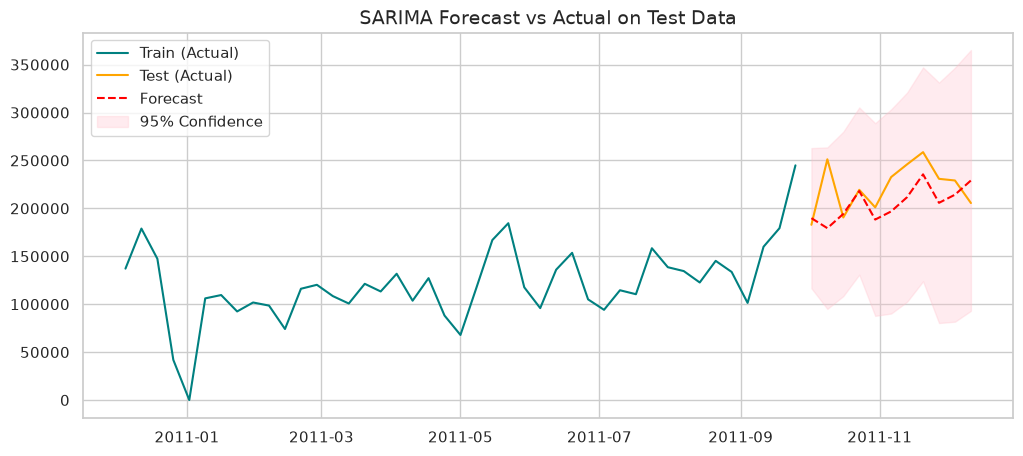

In [15]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Forecast on the test set
test_forecast, test_conf_int = auto_model.predict(n_periods=len(test), return_conf_int=True)
test_forecast.index = test.index

# Calculate Metrics
mae = mean_absolute_error(test, test_forecast)
rmse = np.sqrt(mean_squared_error(test, test_forecast))

# MAPE function (safeguard against division by zero)
def calculate_mape(y_true, y_pred): 
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    return np.mean(np.abs((y_true - y_pred) / np.maximum(np.abs(y_true), 1))) * 100

mape = calculate_mape(test, test_forecast)

metrics_df = pd.DataFrame({
    'Metric': ['MAE', 'RMSE', 'MAPE (%)'],
    'Value': [mae, rmse, mape]
})
print("--- Model Performance on Test Set ---")
display(metrics_df.round(2))

# Plot Test Forecast vs Actual
plt.figure(figsize=(12, 5))
plt.plot(train.index, train.values, label='Train (Actual)', color='teal')
plt.plot(test.index, test.values, label='Test (Actual)', color='orange')
plt.plot(test_forecast.index, test_forecast.values, color='red', label='Forecast', linestyle='--')
plt.fill_between(test.index, test_conf_int[:, 0], test_conf_int[:, 1], color='pink', alpha=0.3, label='95% Confidence')
plt.title('SARIMA Forecast vs Actual on Test Data', fontsize=14)
plt.legend()
plt.show()

### Interpreting the Evaluation Metrics
The performance of the SARIMA model on the unseen Test Set is evaluated using three key metrics:

- **MAE (Mean Absolute Error) ≈ 23,024:** On average, our model's weekly revenue forecast is off by about $23,000 from the actual value.
- **RMSE (Root Mean Squared Error) ≈ 29,830:** RMSE gives a higher penalty to large errors. Since it is not drastically higher than MAE, it indicates that the model doesn't make extreme, catastrophic errors.
- **MAPE (Mean Absolute Percentage Error) ≈ 9.85%:** This is the most intuitive business metric. It means our predictions are, on average, about 9.85% away from the actual revenue. In retail forecasting, **a MAPE under 10% is generally considered highly accurate and excellent for strategic planning.**

### Final Future Projection (Next 12 Weeks)
To get the most accurate prediction for the future, we now retrain our model on the **Entire Dataset (Train + Test)** using the same optimal parameters. We then forecast the next 12 weeks with 95% Confidence Intervals.

In [16]:
# Retrain on full dataset using optimal parameters
print("Retraining on Full Dataset...")
final_model = pm.ARIMA(order=auto_model.order, seasonal_order=auto_model.seasonal_order)
final_model.fit(weekly_sales)

# Forecast Next 12 Weeks
future_periods = 12
future_forecast, future_conf_int = final_model.predict(n_periods=future_periods, return_conf_int=True)

# Generate future dates
last_date = weekly_sales.index[-1]
future_dates = pd.date_range(start=last_date, periods=future_periods + 1, freq='W')[1:]
future_forecast.index = future_dates

# Create Forecast DataFrame
forecast_df = pd.DataFrame({
    'Date': future_dates,
    'Forecasted_Sales': future_forecast.values,
    'Lower_Bound_95': future_conf_int[:, 0],
    'Upper_Bound_95': future_conf_int[:, 1]
}).round(2)

print("\n--- Forecast for the Next 12 Weeks ---")
display(forecast_df)

# Save to CSV
import os
os.makedirs('../data/processed', exist_ok=True)
forecast_df.to_csv('../data/processed/forecast_results.csv', index=False)
print("Forecast results saved to `data/processed/forecast_results.csv`")

Retraining on Full Dataset...

--- Forecast for the Next 12 Weeks ---


,Date,Forecasted_Sales,Lower_Bound_95,Upper_Bound_95
0,2011-12-18,252098.30,177778.28,326418.32
1,2011-12-25,236656.88,153123.36,320190.39
2,2012-01-01,258617.73,172715.52,344519.94
3,2012-01-08,246992.02,158784.70,335199.35
4,2012-01-15,277040.85,176111.18,377970.52
5,2012-01-22,256230.90,149429.46,363032.34
6,2012-01-29,278370.10,167995.69,388744.50
7,2012-02-05,266922.73,153087.44,380758.02
8,2012-02-12,297149.89,169896.65,424403.14
9,2012-02-19,276518.28,142276.94,410759.63


Forecast results saved to `data/processed/forecast_results.csv`


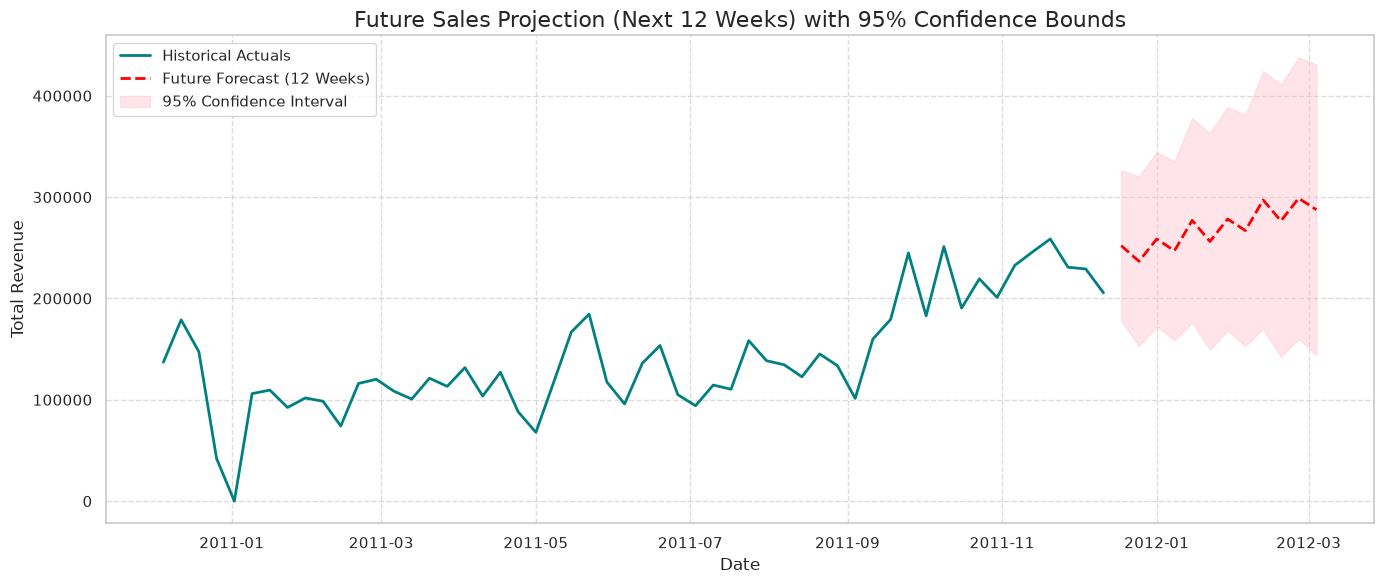

In [17]:
# Final Visualization
plt.figure(figsize=(14, 6))

# Plot historical data
plt.plot(weekly_sales.index, weekly_sales.values, label='Historical Actuals', color='teal', linewidth=2)

# Plot future forecast
plt.plot(future_forecast.index, future_forecast.values, label='Future Forecast (12 Weeks)', color='red', linestyle='--', linewidth=2)

# Shade confidence interval
plt.fill_between(future_forecast.index, 
                 future_conf_int[:, 0], 
                 future_conf_int[:, 1], 
                 color='pink', alpha=0.4, label='95% Confidence Interval')

plt.title('Future Sales Projection (Next 12 Weeks) with 95% Confidence Bounds', fontsize=16)
plt.xlabel('Date')
plt.ylabel('Total Revenue')
plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()